# 04 · Evaluation before optimization

## The engineering question
Can an evaluation score improve even when the system has not found more useful evidence?

**Learning outcomes:** calculate Recall@k, MRR, and nDCG; separate document relevance from chunk/evidence accounting; avoid duplicate credit; handle unanswerable and incompletely judged queries explicitly.

Recall@k divides retrieved relevant documents by the number of relevant documents in the judgments. MRR uses the reciprocal rank of the first relevant result. nDCG discounts graded gains by rank and normalizes by the ideal ordering. We use gain $2^g-1$ and discount $\log_2(r+1)$ for one-based rank $r$.

Our document metrics collapse repeated document revisions before taking the top k. Evidence coverage instead measures the union of retrieved character intervals inside immutable gold source spans. This keeps the evaluation target stable when chunk boundaries change. A no-answer query has no recall denominator; exclude it from relevance means and report its abstention behavior separately.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("04", "T", docker=False)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


In [2]:
from vector_masterclass.metrics import ranking_metrics, aggregate, evidence_coverage
from vector_masterclass.schema import Document, Chunk, SourceSpan, EvidenceUnit

labels = {"A": 2, "B": 1}
ranked = ["noise", "A", "A", "B"]
measured = ranking_metrics(ranked, labels, 3)
display(measured)
ideal = 3 + 1 / np.log2(3)
observed = 3 / np.log2(3) + 1 / 2
assert np.isclose(measured["ndcg"], observed / ideal)
missing = ranking_metrics(["noise"], {}, 3)
display(aggregate([measured, missing]))

{'judgment_coverage': 0.6666666666666666,
 'retrieved': 3,
 'relevant_count': 2,
 'recall': 1.0,
 'mrr': 0.5,
 'ndcg': 0.6590018048024133,
 'no_answer_returned_any': None}

{'queries': 2,
 'recall': 1.0,
 'recall_included': 1,
 'mrr': 0.5,
 'mrr_included': 1,
 'ndcg': 0.6590018048024133,
 'ndcg_included': 1}

,case,naive_sum_fraction,union_fraction,covered_at_0.8
0,overlapping partial chunks,0.8,0.6,0.0
1,complete source coverage,1.2,1.0,1.0


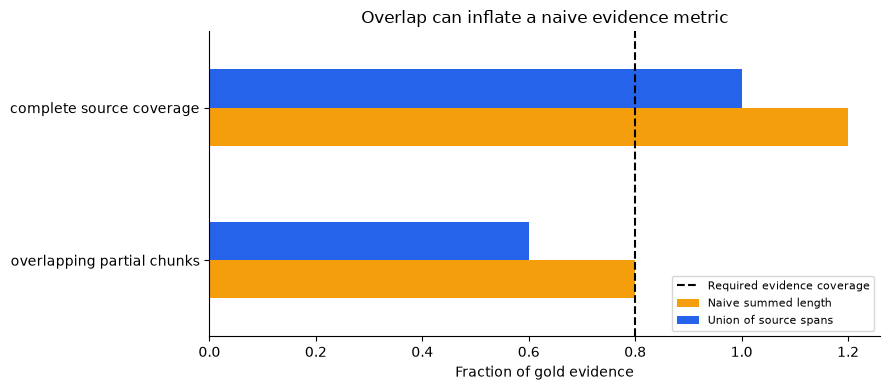

In [3]:
doc = Document(id="demo", revision="1", title="Evidence", text="0123456789")
gold = [
    EvidenceUnit(
        id="fact",
        alternatives=[SourceSpan(document_key=doc.key, source_hash=doc.sha256, start=0, end=10)],
    )
]
duplicated = [Chunk.from_span(doc, 0, 4, "small"), Chunk.from_span(doc, 2, 6, "small")]
complete = duplicated + [Chunk.from_span(doc, 6, 10, "small")]
rows = []
for name, chunks in [
    ("overlapping partial chunks", duplicated),
    ("complete source coverage", complete),
]:
    result = evidence_coverage(chunks, gold)
    rows.append(
        {
            "case": name,
            "naive_sum_fraction": sum(c.end - c.start for c in chunks) / 10,
            "union_fraction": result["unit_fractions"]["fact"],
            "covered_at_0.8": result["coverage"],
        }
    )
results = lesson.table(pd.DataFrame(rows))
display(results)
fig, ax = plt.subplots(figsize=(9, 4))
results.set_index("case")[["naive_sum_fraction", "union_fraction"]].rename(
    columns={"naive_sum_fraction": "Naive summed length", "union_fraction": "Union of source spans"}
).plot.barh(ax=ax, color=["#f59e0b", "#2563eb"])
ax.axvline(0.8, linestyle="--", color="black", label="Required evidence coverage")
ax.set(
    xlabel="Fraction of gold evidence",
    ylabel="",
    title="Overlap can inflate a naive evidence metric",
)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Failure, exercise, and decisions
The partial chunks cover only 60% of the evidence even though their lengths sum to 80%. Adding more overlapping chunks could make the naive score exceed 100%. This is a metric bug, not a retrieval gain.

**Exercise:** change the gold coverage threshold from 0.8 to 1.0 and add a one-character gap. Explain why a threshold is an evaluation convention that must be fixed before tuning. Add a second alternative source span supporting the same fact; it should not create a second required fact.

Use supplied qrels for public-benchmark comparability, but report judgment coverage and acknowledge that unjudged does not mean known irrelevant. Use human-reviewed evidence spans for controlled chunking experiments. In production, audit query slices and user outcomes as well as aggregate scores; good ANN recall is a different question from human relevance.

In [4]:
manifest = lesson.finish(
    {
        "hand_computed_ndcg": bool(np.isclose(measured["ndcg"], observed / ideal)),
        "no_answer_excluded": missing["recall"] is None,
        "overlap_not_double_counted": float(results.iloc[0]["union_fraction"]) == 0.6,
        "full_evidence_covered": float(results.iloc[1]["covered_at_0.8"]) == 1,
    }
)

{
  "artifact": "artifacts/20261031T043038Z-676551/04",
  "checks": {
    "hand_computed_ndcg": true,
    "no_answer_excluded": true,
    "overlap_not_double_counted": true,
    "full_evidence_covered": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.